# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [5]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [6]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


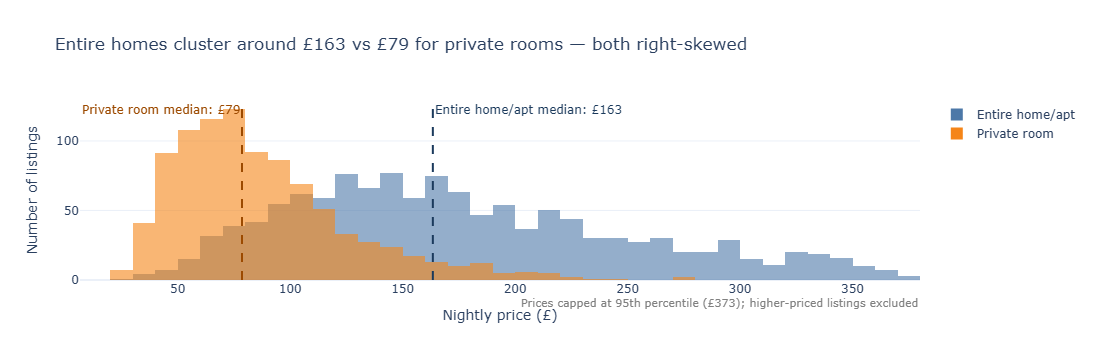

In [7]:
# Task 1
df1 = df_cap[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])]
med = df1.groupby('room_type')['price'].median()

bar_col  = {'Entire home/apt': '#4C78A8', 'Private room': '#F58518'}
line_col = {'Entire home/apt': '#1B3A5C', 'Private room': '#9C4A00'}

fig = px.histogram(
    df1, x='price', color='room_type', nbins=50,
    barmode='overlay', opacity=0.6,
    color_discrete_map=bar_col,
    labels={'price': 'Nightly price (£)', 'room_type': 'Room type'},
    title=(f"Entire homes cluster around £{med['Entire home/apt']:.0f} vs "
           f"£{med['Private room']:.0f} for private rooms — both right-skewed"),
)

# Median line per room type (darker shade of its bar colour)
positions = {'Entire home/apt': 'top right', 'Private room': 'top left'}
for rt, m in med.items():
    fig.add_vline(
        x=m, line_dash='dash', line_width=2, line_color=line_col[rt],
        annotation_text=f"{rt} median: £{m:.0f}",
        annotation_position=positions[rt],
        annotation_font_color=line_col[rt],
    )

# Outlier-cap note
fig.add_annotation(
    xref='paper', yref='paper', x=1, y=-0.18, showarrow=False,
    text=f"Prices capped at 95th percentile (£{p95:.0f}); higher-priced listings excluded",
    font=dict(size=11, color='grey'), xanchor='right',
)

fig.update_layout(template='plotly_white', legend_title_text='', yaxis_title='Number of listings')
fig.show()


## Task 2 - Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

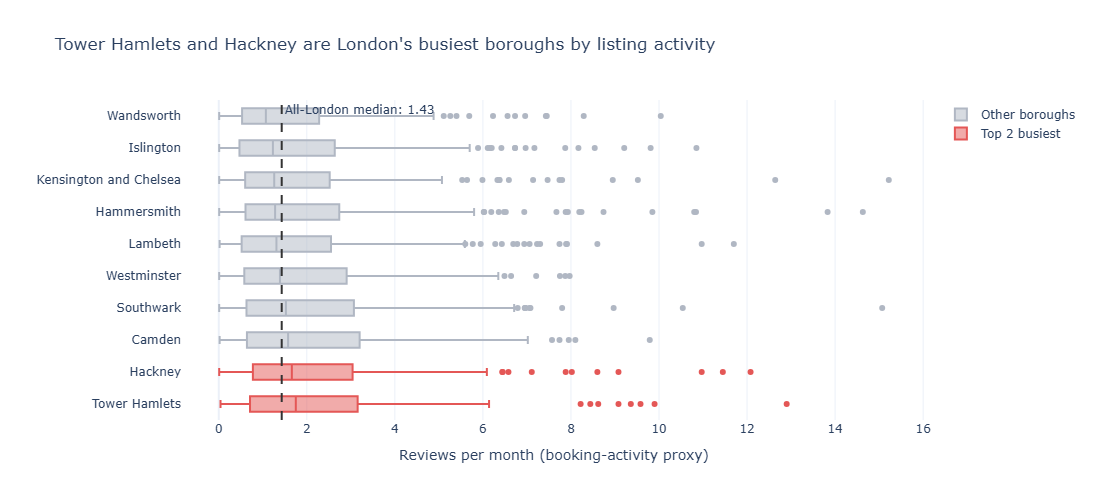

In [8]:
# Task 2
df2 = df[df['reviews_per_month'].fillna(0) > 0].copy()

# Order boroughs by median; Plotly draws the first category at the bottom,
# so ascending order puts the most active at the top
order = df2.groupby('neighbourhood')['reviews_per_month'].median().sort_values()
top2 = order.index[-2:][::-1].tolist()          # [busiest, second busiest]

df2['highlight'] = np.where(df2['neighbourhood'].isin(top2), 'Top 2 busiest', 'Other boroughs')

fig = px.box(
    df2, x='reviews_per_month', y='neighbourhood',
    color='highlight', orientation='h', points='outliers',
    category_orders={'neighbourhood': order.index.tolist()},
    color_discrete_map={'Top 2 busiest': '#E45756', 'Other boroughs': '#B0B7C3'},
    labels={'reviews_per_month': 'Reviews per month (booking-activity proxy)',
            'neighbourhood': ''},
    title=f"{top2[0]} and {top2[1]} are London's busiest boroughs by listing activity",
)

# Overall median reference line
overall = df2['reviews_per_month'].median()
fig.add_vline(
    x=overall, line_dash='dash', line_color='#333',
    annotation_text=f"All-London median: {overall:.2f}",
    annotation_position='top right',
)

fig.update_layout(template='plotly_white', legend_title_text='',
                  boxmode='overlay', height=max(500, 22 * len(order)))
fig.show()
